TITANIC DATASET EDA

First 5 Records:
   PassengerId  Survived  Pclass                    Name     Sex   Age  SibSp  \
0            1         0       3        King, Mr. Edward    male  42.5      0   
1            2         1       2  Walker, Miss. Margaret  female  26.5      0   
2            3         0       3      Walker, Mr. Edward    male  30.1      0   
3            4         0       3      Thomas, Mr. George    male   0.5      0   
4            5         0       1        Clark, Mr. James    male  21.8      0   

   Parch     Ticket   Fare Cabin Embarked  
0      1   CA 45080  16.24   NaN        Q  
1      0  A/5 67858  19.09   NaN        S  
2      4  A/5 84270   4.00   NaN        S  
3      0  W/C 99108   5.09   NaN        C  
4      0   PC 17016  21.76   B73        Q  

Dataset Shape (Rows, Columns):
(300, 12)

Column Data Types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp      

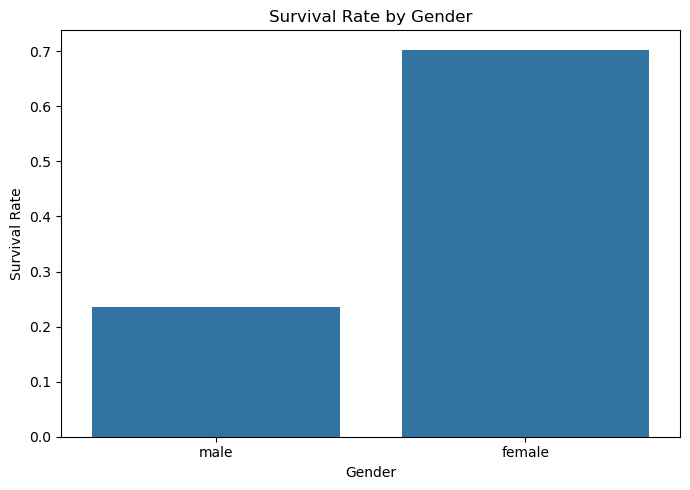

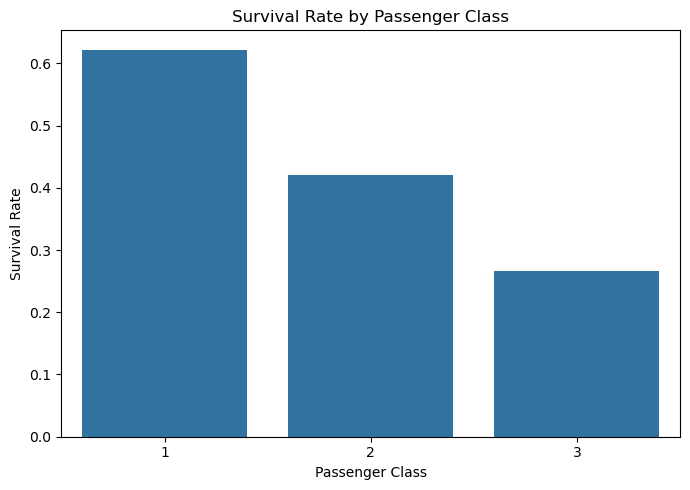

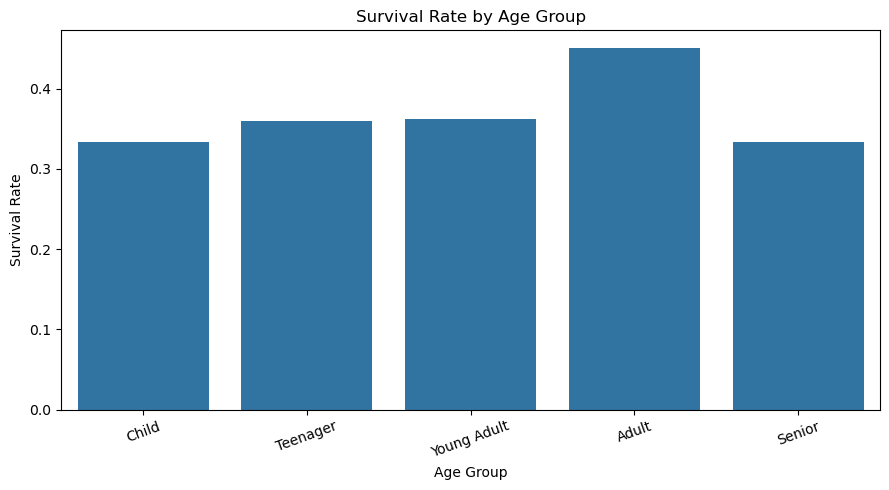

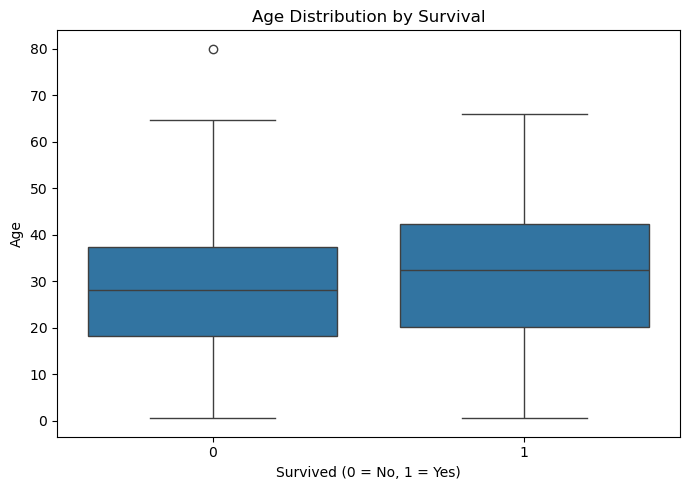

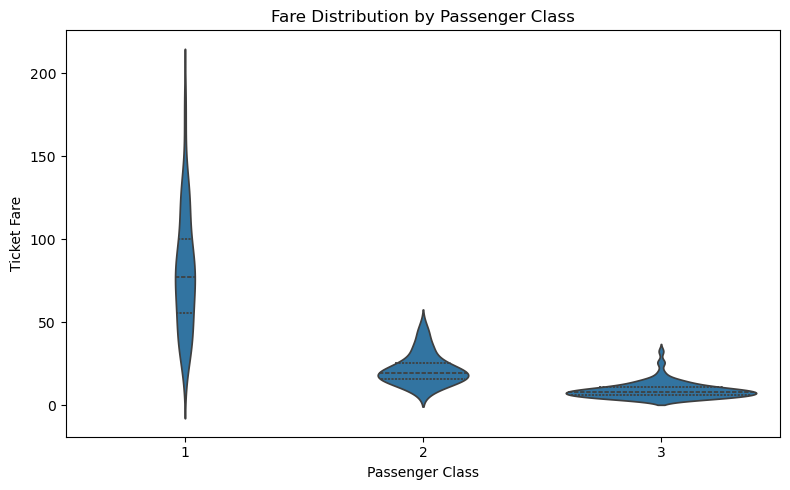


FINAL INSIGHT REPORT
1. Overall survival rate was 39.33%.
2. Female survival rate was 70.30%, while male survival rate was 23.62%.
3. First-class survival rate was 62.20%, compared with 26.71% in third class.
4. Age and survival relationship is explored using the age-group bar chart and age boxplot.
5. Fare differences across passenger classes are explored using the violin plot.

Analyzed dataset saved as titanic_eda_results.csv


In [1]:
# Project 1: Titanic dataset EDA

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load dataset
df = pd.read_csv("titanic_dataset.csv")

print("TITANIC DATASET EDA")
print("=" * 50)

# 2. Inspect the dataset
print("\nFirst 5 Records:")
print(df.head())

print("\nDataset Shape (Rows, Columns):")
print(df.shape)

print("\nColumn Data Types:")
print(df.dtypes)

# 3. Inspect missing values
print("\nMissing Values:")
print(df.isnull().sum())

print("\nMissing Values Percentage:")
print((df.isnull().mean() * 100).round(2))

# 4. Basic statistical summary
print("\nStatistical Summary:")
print(df.describe())

# 5. Overall survival rate
survival_rate = df["Survived"].mean() * 100
print(f"\nOverall Survival Rate: {survival_rate:.2f}%")

print("\nSurvival Counts (0 = No, 1 = Yes):")
print(df["Survived"].value_counts())

# 6. Survival rate by sex
print("\nSurvival Rate by Sex (%):")
print((df.groupby("Sex")["Survived"].mean() * 100).round(2))

# 7. Survival rate by passenger class
print("\nSurvival Rate by Passenger Class (%):")
print((df.groupby("Pclass")["Survived"].mean() * 100).round(2))

# 8. Create age groups
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"],
    include_lowest=True
)

print("\nSurvival Rate by Age Group (%):")
print((df.groupby("AgeGroup", observed=False)["Survived"].mean() * 100).round(2))

# 9. Bar chart: Survival by sex
plt.figure(figsize=(7, 5))
sns.barplot(data=df, x="Sex", y="Survived", errorbar=None)
plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")
plt.tight_layout()
plt.show()

# 10. Bar chart: Survival by passenger class
plt.figure(figsize=(7, 5))
sns.barplot(data=df, x="Pclass", y="Survived", errorbar=None)
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.tight_layout()
plt.show()

# 11. Bar chart: Survival by age group
plt.figure(figsize=(9, 5))
sns.barplot(
    data=df, x="AgeGroup", y="Survived",
    errorbar=None
)
plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 12. Boxplot: Age distribution by survival
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Survived", y="Age")
plt.title("Age Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

# 13. Violin plot: Fare by passenger class
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="Pclass", y="Fare", inner="quartile")
plt.title("Fare Distribution by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Ticket Fare")
plt.tight_layout()
plt.show()

# 14. Insight report
sex_rates = df.groupby("Sex")["Survived"].mean() * 100
class_rates = df.groupby("Pclass")["Survived"].mean() * 100

print("\n" + "=" * 50)
print("FINAL INSIGHT REPORT")
print("=" * 50)

print(f"1. Overall survival rate was {survival_rate:.2f}%.")

print(
    f"2. Female survival rate was {sex_rates['female']:.2f}%, "
    f"while male survival rate was {sex_rates['male']:.2f}%.")

print(
    f"3. First-class survival rate was {class_rates[1]:.2f}%, "
    f"compared with {class_rates[3]:.2f}% in third class."
)

print(
    "4. Age and survival relationship is explored using the age-group "
    "bar chart and age boxplot."
)

print(
    "5. Fare differences across passenger classes are explored "
    "using the violin plot."
)

# 15. Save the analyzed dataset
df.to_csv("titanic_eda_results.csv", index=False)
print("\nAnalyzed dataset saved as titanic_eda_results.csv")